# Gradient Boosting - Base P-COLD

Mémoire M2 EGRF - Détection et pilotage du risque opérationnel bancaire

## Objectif

Conformément à la méthodologie (architecture inspirée de la Loss Distribution Approach), le Gradient Boosting est mobilisé selon une double logique :
- **Classification** : prédire si un événement est une fraude (même cible binaire que le logit et le Random Forest)
- **Régression** : prédire la sévérité (`log_loss`) à partir des caractéristiques de l'événement

Contrairement au Random Forest, où les arbres sont indépendants et agrégés par vote, le Gradient Boosting construit ses arbres de façon séquentielle : chaque nouvel arbre corrige les erreurs des arbres précédents.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier, XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                              classification_report, accuracy_score, ConfusionMatrixDisplay,
                              mean_squared_error, mean_absolute_error, r2_score)

plt.rcParams['figure.figsize'] = (8, 5)

In [11]:
df = pd.read_csv(
    r"D:\Université De Rouen\Mémoire_HAMED_ROUEN\Base\pcold_clean.csv",
    sep=";"
)
df['Y_fraude'] = df['type_evenement'].isin(['Internal fraud', 'External fraud']).astype(int)
print(f"{len(df)} événements chargés.")

3722 événements chargés.


## Partie 1 : Volet classification (type d'événement)

### 1.1 Préparation des données

Mêmes variables explicatives et même découpage train/test que pour le logit et le Random Forest, afin de garder une comparaison directe entre les trois modèles.

In [12]:
variables_explicatives = ['Business line', 'log_loss']
df_modele = df[variables_explicatives + ['Y_fraude']].dropna()

X = pd.get_dummies(df_modele[['Business line']], drop_first=True).astype(float)
X['log_loss'] = df_modele['log_loss']
y = df_modele['Y_fraude']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Train : {len(X_train)} | Test : {len(X_test)}")

Train : 2791 | Test : 931


### 1.2 Entraînement

Quelques paramètres clés :
- `n_estimators=300` : nombre d'arbres ajoutés séquentiellement (M dans la méthodologie)
- `learning_rate=0.05` : le taux d'apprentissage ν, qui pondère la contribution de chaque nouvel arbre — une valeur faible rend l'apprentissage plus progressif et limite le risque de surapprentissage
- `max_depth=4` : profondeur maximale de chaque arbre, volontairement limitée car en boosting, des arbres peu profonds ("weak learners") suffisent et se combinent mieux
- `scale_pos_weight` : équivalent du `class_weight='balanced'` du Random Forest, pour compenser le déséquilibre entre fraude et non-fraude

In [13]:
poids_positif = (y_train == 0).sum() / (y_train == 1).sum()

gb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=poids_positif,
    random_state=42,
    eval_metric='logloss'
)
gb.fit(X_train, y_train)

y_pred = gb.predict(X_test)
y_proba = gb.predict_proba(X_test)[:, 1]
print("Modèle entraîné.")

Modèle entraîné.


### 1.3 Évaluation

In [15]:
print(classification_report(y_test, y_pred, target_names=['Non-fraude', 'Fraude']))
auc = roc_auc_score(y_test, y_proba)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"AUC      : {auc:.4f}")

              precision    recall  f1-score   support

  Non-fraude       0.77      0.73      0.75       310
      Fraude       0.87      0.89      0.88       621

    accuracy                           0.84       931
   macro avg       0.82      0.81      0.81       931
weighted avg       0.84      0.84      0.84       931

Accuracy : 0.8378
AUC      : 0.8726


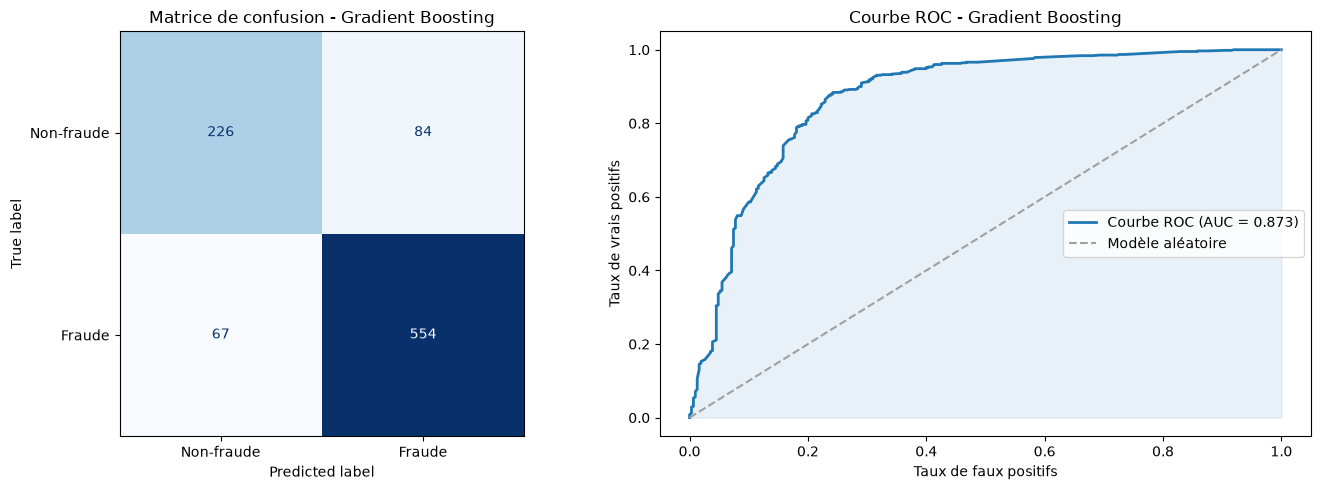

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

matrice = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=matrice, display_labels=['Non-fraude', 'Fraude'])
disp.plot(cmap='Blues', values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title("Matrice de confusion - Gradient Boosting")

taux_fp, taux_vp, seuils = roc_curve(y_test, y_proba)
axes[1].plot(taux_fp, taux_vp, color='#1f77b4', linewidth=2, label=f'Courbe ROC (AUC = {auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='#a0a0a0', linestyle='--', label='Modèle aléatoire')
axes[1].fill_between(taux_fp, taux_vp, alpha=0.1, color='#1f77b4')
axes[1].set_xlabel("Taux de faux positifs")
axes[1].set_ylabel("Taux de vrais positifs")
axes[1].set_title("Courbe ROC - Gradient Boosting")
axes[1].legend()
plt.tight_layout()
plt.savefig("D:/Université De Rouen/Mémoire_HAMED_ROUEN/Figures/ROC_GRADIENT.png", dpi=300, bbox_inches="tight")
plt.show()

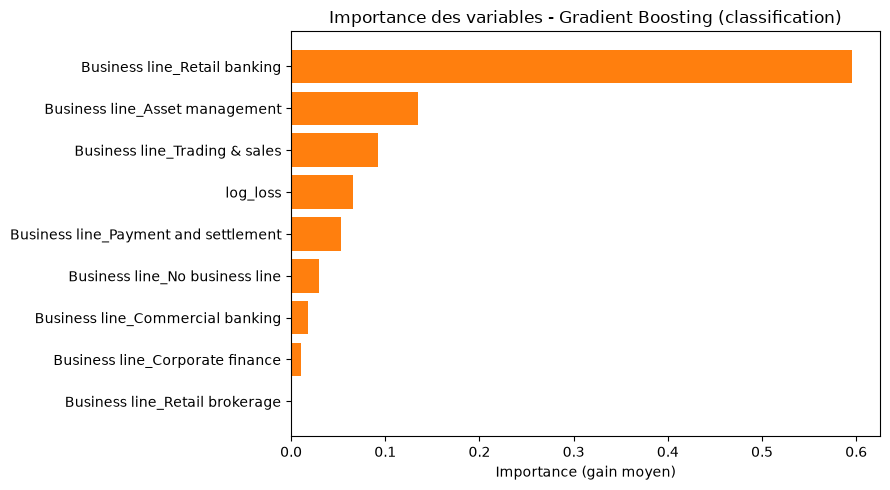

In [18]:
importance_classif = pd.DataFrame({
    'Variable': X.columns,
    'Importance': gb.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(9, 5))
plt.barh(importance_classif['Variable'], importance_classif['Importance'], color='#ff7f0e')
plt.xlabel("Importance (gain moyen)")
plt.title("Importance des variables - Gradient Boosting (classification)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("D:/Université De Rouen/Mémoire_HAMED_ROUEN/Figures/Importance_gradient.png", dpi=300, bbox_inches="tight")
plt.show()

**Lecture** : le Gradient Boosting obtient une accuracy de 83,8 % et une AUC de 0,873, légèrement supérieures au Random Forest (83,7 %, 0,867) et au logit (83,0 %). `Retail banking` domine ici largement l'importance des variables, suivie d'`Asset management`.

## Partie 2 : Volet régression (sévérité)

### 2.1 Préparation des données

Pour ce volet, la variable à expliquer est `log_loss`. Les variables explicatives sont le type d'événement et la ligne métier — le montant de perte lui-même n'est bien sûr pas utilisé comme variable explicative, puisque `log_loss` en est directement dérivé (cela créerait une fuite de données triviale).

In [19]:
variables_explicatives_reg = ['type_evenement', 'Business line']
df_modele_reg = df[variables_explicatives_reg + ['log_loss']].dropna()

X_reg = pd.get_dummies(df_modele_reg[variables_explicatives_reg], drop_first=True).astype(float)
y_reg = df_modele_reg['log_loss']

print(f"N utilisées : {len(df_modele_reg)}")

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=42
)

N utilisées : 3722


### 2.2 Entraînement

Même logique d'hyperparamètres que pour la classification, mais avec `XGBRegressor` : la fonction de perte devient l'erreur quadratique plutôt que la log-vraisemblance (voir méthodologie).

In [20]:
gb_reg = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    random_state=42
)
gb_reg.fit(X_train_reg, y_train_reg)

y_pred_reg = gb_reg.predict(X_test_reg)
print("Modèle entraîné.")

Modèle entraîné.


### 2.3 Évaluation

Trois métriques usuelles pour la régression :
- **RMSE** (racine de l'erreur quadratique moyenne) : pénalise davantage les grosses erreurs
- **MAE** (erreur absolue moyenne) : plus facile à interpréter, dans l'unité de `log_loss`
- **R²** : proportion de la variance de la sévérité expliquée par le modèle

In [21]:
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
mae = mean_absolute_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)

print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R²   : {r2:.4f}")

RMSE : 2.4548
MAE  : 1.8252
R²   : 0.4046


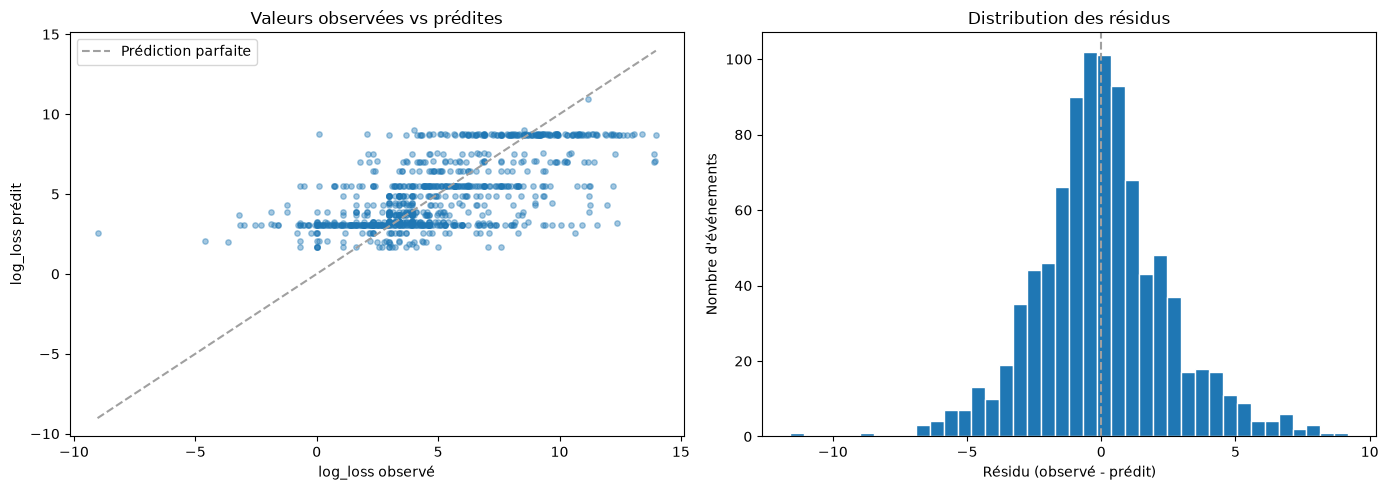

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test_reg, y_pred_reg, alpha=0.4, color='#1f77b4', s=15)
lims = [min(y_test_reg.min(), y_pred_reg.min()), max(y_test_reg.max(), y_pred_reg.max())]
axes[0].plot(lims, lims, color='#a0a0a0', linestyle='--', label='Prédiction parfaite')
axes[0].set_xlabel("log_loss observé")
axes[0].set_ylabel("log_loss prédit")
axes[0].set_title("Valeurs observées vs prédites")
axes[0].legend()

residus = y_test_reg - y_pred_reg
axes[1].hist(residus, bins=40, color='#1f77b4', edgecolor='white')
axes[1].axvline(0, color='#a0a0a0', linestyle='--')
axes[1].set_xlabel("Résidu (observé - prédit)")
axes[1].set_ylabel("Nombre d'événements")
axes[1].set_title("Distribution des résidus")

plt.tight_layout()
plt.savefig("D:/Université De Rouen/Mémoire_HAMED_ROUEN/Figures/observeesVSpredites.png", dpi=300, bbox_inches="tight")
plt.show()

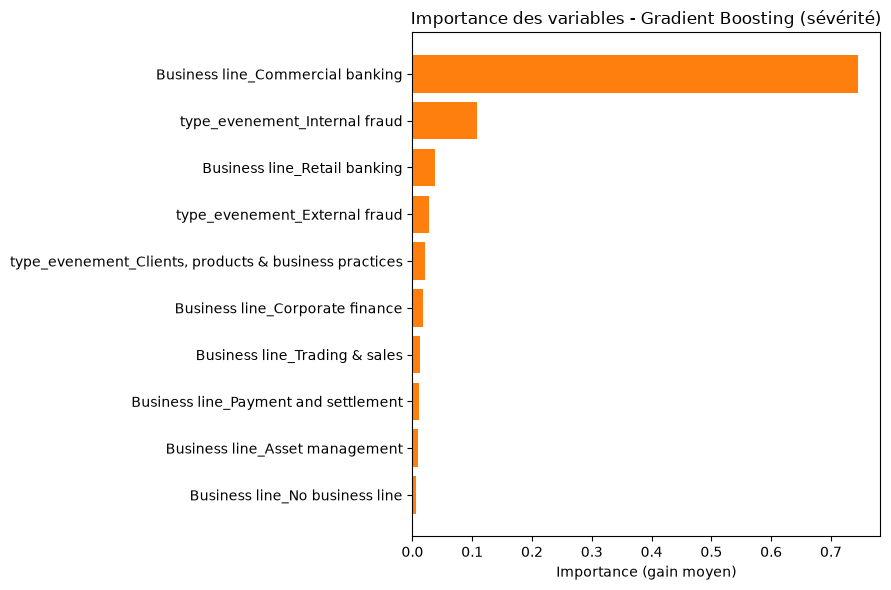

In [23]:
importance_reg = pd.DataFrame({
    'Variable': X_reg.columns,
    'Importance': gb_reg.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(9, 6))
plt.barh(importance_reg['Variable'].head(10), importance_reg['Importance'].head(10), color='#ff7f0e')
plt.xlabel("Importance (gain moyen)")
plt.title("Importance des variables - Gradient Boosting (sévérité)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("D:/Université De Rouen/Mémoire_HAMED_ROUEN/Figures/Importance_regression.png", dpi=300, bbox_inches="tight")
plt.show()

**Lecture** : le modèle explique environ 40 % de la variance de la sévérité (R² = 0,40) à partir du seul type d'événement et de la ligne métier, ce qui reste correct compte tenu de la nature très bruitée des montants de perte. La ligne métier `Commercial banking` domine très largement l'importance des variables, ce qui mérite d'être interprété avec prudence dans la discussion des résultats, notamment au regard du faible nombre d'observations dans cette catégorie.